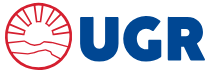

**Trabajo Final** - Ariel Fernandez  : *Clasificación del riesgo de derivación a Gestión Judicial en una cartera de préstamos personales mediante aprendizaje automático supervisado*


# Modelo con XGBoost para clasificar el riesgo de Gestión Judicial

Este notebook entrena los modelos XGBoost de **Apertura** y **Renovación** con los préstamos de **2024–2025 con desenlace conocido**, utilizando la configuración seleccionada previamente.

Luego toma la cartera de préstamos de 2026 disponible al **01/04/2026**, genera y guarda las clasificaciones y, recién después, consulta los resultados reales observados al **01/09/2026**. De esta manera, la predicción se realiza con la información disponible en abril y la comparación se efectúa con los pases posteriores a Gestión Judicial.

## Configuración seleccionada

| Población | Peso Judicial: score <600 | Peso Judicial: score 600–799 | Peso Judicial: score 800+ | Umbral |
|---|---:|---:|---:|---:|
| Apertura | 0,78 | 1,50 | 2,50 | 0,38 |
| Renovación | 4,00 | 5,00 | 6,00 | 0,40 |

Para evitar una doble ponderación de la clase Judicial, el entrenamiento utiliza los pesos segmentados mediante `sample_weight` y mantiene `scale_pos_weight=1.0`.

**Variables finales:** 14 en Apertura y 20 en Renovación. Ambas poblaciones incluyen **sueldo, monto de cuota y relación cuota-ingreso**.

El entrenamiento final utiliza todas las operaciones de 2024–2025 con desenlace conocido. La separación por cliente en Train/Test y en validación cruzada corresponde al desarrollo realizado en el notebook 02. Este código aplica la configuración final a 2026, sin utilizar ese período para entrenar.


## Indice metodológico

1. Configurar el entorno e importar las librerías necesarias.
2. Cargar la base histórica de entrenamiento y la cartera de validación disponible al 01/04/2026.
3. Definir la base de entrenamiento con préstamos de 2024–2025 con desenlace conocido.
4. Construir el target Judicial / No Judicial y separar Apertura de Renovación.
5. Definir las variables, rangos de score, pesos, umbrales e hiperparámetros seleccionados.
6. Construir el preprocesamiento y los modelos XGBoost.
7. Entrenar y guardar los modelos de Apertura y Renovación con 2024–2025.
8. Seleccionar la cartera que permanecía activa al 01/04/2026.
9. Verificar la integridad de las variables requeridas para clasificar.
10. Clasificar la cartera de 2026 sin utilizar desenlaces posteriores.
11. Guardar las predicciones antes de consultar los resultados reales.
12. Leer los pases a Gestión Judicial y los saldos observados al 01/09/2026.
13. Vincular las predicciones con los resultados reales mediante el número de factura.
14. Medir la detección de judiciales por población y rango de score.
15. Identificar las alertas que permanecen pendientes de observación.
16. Mostrar las curvas precisión-recall y matrices de confusión de los casos con desenlace conocido.
17. Exportar la configuración, las predicciones y los resultados de la aplicación.

## 1. Configuración e importación de librerías

In [ ]:
!pip -q install xgboost openpyxl joblib

import json
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings('ignore')

from pathlib import Path
import numpy as np
import pandas as pd
import joblib

from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    confusion_matrix, precision_score, recall_score,
    f1_score, fbeta_score, average_precision_score
)
from xgboost import XGBClassifier

pd.set_option('display.max_columns', 150)
pd.set_option('display.max_rows', 250)

RANDOM_STATE = 42
FECHA_PREDICCION = pd.Timestamp('2026-04-01')
FECHA_COMPARACION = pd.Timestamp('2026-09-01')

print('Entorno listo.')
print('Fecha de la cartera:', FECHA_PREDICCION.date())
print('Fecha de comparación:', FECHA_COMPARACION.date())

Entorno listo.
Fecha de la cartera: 2026-04-01
Fecha de comparación: 2026-09-01


## 2. Carga de las bases de datos

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

BASE_DIR = Path('/content/drive/MyDrive/PROYECTO TESIS/SEMINARIO')
RUTA_BASE_ENTRENAMIENTO = BASE_DIR / 'dataset2326v2.xlsx'
RUTA_BASE_VALIDACION = BASE_DIR / 'data2026validacion.xlsx'
RUTA_RESULTADOS_REALES = BASE_DIR / 'dataset2326v2.xlsx'
RUTA_MODELO_APERTURA = BASE_DIR / 'MODELO_FINAL_APERTURA_XGB_SEGMENTADO.joblib'
RUTA_MODELO_RENOVACION = BASE_DIR / 'MODELO_FINAL_RENOVACION_XGB_SEGMENTADO.joblib'
RUTA_PREDICCIONES_CIEGAS = BASE_DIR / 'PREDICCIONES_CARTERA_2026_AL_01_04.xlsx'
RUTA_RESULTADOS_2026 = BASE_DIR / 'RESULTADOS_VALIDACION_2026_AL_01_09.xlsx'

for ruta in [RUTA_BASE_ENTRENAMIENTO, RUTA_BASE_VALIDACION, RUTA_RESULTADOS_REALES]:
    if not ruta.exists():
        raise FileNotFoundError(f'No se encontró el archivo: {ruta}')

df = pd.read_excel(RUTA_BASE_ENTRENAMIENTO)
df.columns = [str(c).strip() for c in df.columns]

base_validacion = pd.read_excel(RUTA_BASE_VALIDACION)
base_validacion.columns = [str(c).strip() for c in base_validacion.columns]

# Normalizar la clave de operación de la base de validación.
# Se admite tanto "factura" como "operacion" porque el nombre puede
# variar entre las extracciones, pero ambas identifican el préstamo.
columnas_normalizadas = {
    str(c).strip().lower().replace('ó', 'o'): c
    for c in base_validacion.columns
}
columna_clave = next(
    (columnas_normalizadas[c] for c in ['factura', 'operacion']
     if c in columnas_normalizadas),
    None
)
if columna_clave is None:
    raise KeyError(
        'No se encontró la clave del préstamo. '
        'La base debe contener una columna factura u operacion. '
        f'Columnas disponibles: {base_validacion.columns.tolist()}'
    )
if columna_clave != 'factura':
    base_validacion = base_validacion.rename(columns={columna_clave: 'factura'})

print('Base histórica:', df.shape)
print('Base de validación:', base_validacion.shape)
print('Clave utilizada para vincular préstamos: factura')


Mounted at /content/drive
Base histórica: (48668, 40)
Base de validación: (3036, 40)
Clave utilizada para vincular préstamos: factura


## 3. Definición de la base de entrenamiento 2024–2025

In [ ]:

hist = df[
    pd.to_numeric(df['añofac'], errors='coerce').between(2024, 2025)
].copy()

target_num = pd.to_numeric(hist['target'], errors='coerce')

hist['judicial_bin'] = np.where(
    target_num.isin([2, 5]),
    1,
    np.where(
        target_num.isin([3, 4]),
        0,
        np.nan
    )
)

hist = hist[hist['judicial_bin'].notna()].copy()
hist['judicial_bin'] = hist['judicial_bin'].astype(int)

sueldo = pd.to_numeric(hist['SUELDO'], errors='coerce')
cuota = pd.to_numeric(hist['monto_cuota'], errors='coerce')

hist['relacion_cuota_ingreso'] = np.where(
    sueldo > 0,
    cuota / sueldo * 100,
    np.nan
)

tipo = hist['tipocredito'].astype(str).str.upper().str.strip()

poblaciones_hist = {
    'Apertura': hist[
        tipo.str.contains('APERTURA', na=False)
    ].copy().reset_index(drop=True),

    'Renovación': hist[
        tipo.str.contains('RENOV', na=False)
    ].copy().reset_index(drop=True)
}

for nombre, datos in poblaciones_hist.items():
    print(
        f"{nombre}: {len(datos):,} operaciones | "
        f"Judicial={int(datos['judicial_bin'].sum()):,} | "
        f"No Judicial={int((datos['judicial_bin']==0).sum()):,} | "
        f"% Judicial={datos['judicial_bin'].mean():.2%}"
    )


Apertura: 10,797 operaciones | Judicial=6,062 | No Judicial=4,735 | % Judicial=56.15%
Renovación: 14,497 operaciones | Judicial=3,775 | No Judicial=10,722 | % Judicial=26.04%


## 4. Variables y configuración final

Se conserva la configuración seleccionada en el notebook 02: **14 variables para Apertura y 20 para Renovación**. En ambas se mantienen **sueldo, monto de cuota y relación cuota-ingreso**. Los hiperparámetros, pesos segmentados y umbrales se incluyen a continuación y no se reajustan utilizando los resultados de 2026.


In [ ]:
# Configuración final seleccionada en el notebook 02.
configuracion_02 = {'variables': {'Apertura': ['rscore',
                            'capitalprestado',
                            'plan',
                            'SUELDO',
                            'interes',
                            'totalfac',
                            'costo_credito',
                            'monto_cuota',
                            'actividad',
                            'rangoedad',
                            'genero',
                            'provincia',
                            'sucursal',
                            'relacion_cuota_ingreso'],
               'Renovación': ['SUELDO',
                              'monto_cuota',
                              'rscore',
                              'capitalprestado',
                              'plan',
                              'interes',
                              'totalfac',
                              'costo_credito',
                              'actividad',
                              'rangoedad',
                              'genero',
                              'provincia',
                              'sucursal',
                              'relacion_cuota_ingreso',
                              'antiguedad_credito',
                              'cantidad_prestamos_anteriores',
                              'tuvo_mora_anterior',
                              'max_mora_prestamos_anteriores',
                              'prestamos_cancelados_normal',
                              'prestamos_en_judicial_anteriores']},
 'hiperparametros': {'Apertura': {'modelo__subsample': 0.95,
                                  'modelo__reg_lambda': 5,
                                  'modelo__reg_alpha': 0.5,
                                  'modelo__n_estimators': 700,
                                  'modelo__min_child_weight': 5,
                                  'modelo__max_depth': 3,
                                  'modelo__learning_rate': 0.06,
                                  'modelo__colsample_bytree': 0.7},
                     'Renovación': {'modelo__subsample': 0.7,
                                    'modelo__reg_lambda': 5,
                                    'modelo__reg_alpha': 0.5,
                                    'modelo__n_estimators': 800,
                                    'modelo__min_child_weight': 1,
                                    'modelo__max_depth': 4,
                                    'modelo__learning_rate': 0.03,
                                    'modelo__colsample_bytree': 0.95}},
 'pesos_segmentados': {'Apertura': {'<600': 0.78, '600-799': 1.5, '800+': 2.5},
                       'Renovación': {'<600': 4.0, '600-799': 5.0, '800+': 6.0}},
 'umbrales': {'Apertura': 0.38, 'Renovación': 0.4}}

VARIABLES = configuracion_02['variables']
for nombre, cantidad in [('Apertura', 14), ('Renovación', 20)]:
    if len(VARIABLES[nombre]) != cantidad or len(set(VARIABLES[nombre])) != cantidad:
        raise ValueError(f'{nombre}: cantidad de variables incorrecta.')
    if not {'SUELDO', 'monto_cuota', 'relacion_cuota_ingreso'} <= set(VARIABLES[nombre]):
        raise ValueError(f'{nombre}: faltan sueldo, cuota o relación cuota-ingreso.')
    faltantes = [v for v in VARIABLES[nombre] if v not in poblaciones_hist[nombre].columns]
    if faltantes:
        raise KeyError(f'{nombre}: faltan columnas {faltantes}')
    print(f'{nombre}: {len(VARIABLES[nombre])} variables.')


Apertura: 14 variables.
Renovación: 20 variables.


## 5. Agrupación del score

In [ ]:

def agrupar_score(x):
    if pd.isna(x):
        return 'Sin dato'

    # Si viene como valor numérico
    try:
        val = float(x)
        if val < 600:
            return '<600'
        elif val < 800:
            return '600-799'
        else:
            return '800+'
    except:
        pass

    # Si viene como rango categórico
    s = (
        str(x)
        .strip()
        .upper()
        .replace('–', '-')
        .replace('—', '-')
    )

    if s in [
        '0-299', '200-299', '300-399',
        '400-449', '450-499', '500-599'
    ]:
        return '<600'

    if s in ['600-699', '700-799']:
        return '600-799'

    if s in ['800-899', '>900', '900+', '>=900']:
        return '800+'

    return 'Sin dato'


## 6. Pesos, umbrales e hiperparámetros seleccionados

In [ ]:
PESOS_SEGMENTADOS = configuracion_02['pesos_segmentados']
UMBRALES_FINAL = configuracion_02['umbrales']
PARAMS_FINAL = {
    nombre: {k.removeprefix('modelo__'): v for k, v in parametros.items()}
    for nombre, parametros in configuracion_02['hiperparametros'].items()
}
for nombre in ['Apertura', 'Renovación']:
    if not 0 < UMBRALES_FINAL[nombre] < 1:
        raise ValueError(f'Umbral inválido: {nombre}')
    if set(PESOS_SEGMENTADOS[nombre]) != {'<600', '600-799', '800+'}:
        raise ValueError(f'Pesos incompletos: {nombre}')
    if any(p <= 0 for p in PESOS_SEGMENTADOS[nombre].values()):
        raise ValueError(f'Pesos inválidos: {nombre}')

tabla_cfg = pd.DataFrame([
    {'Población': poblacion, 'Score': score,
     'Peso Judicial': peso, 'Umbral': UMBRALES_FINAL[poblacion]}
    for poblacion, pesos in PESOS_SEGMENTADOS.items()
    for score, peso in pesos.items()
])
display(tabla_cfg)

,Población,Score,Peso Judicial,Umbral
0,Apertura,<600,0.78,0.38
1,Apertura,600-799,1.50,0.38
2,Apertura,800+,2.50,0.38
3,Renovación,<600,4.00,0.40
4,Renovación,600-799,5.00,0.40
5,Renovación,800+,6.00,0.40


## 7. Preprocesamiento de las variables

In [ ]:

def columnas_por_tipo(datos, variables):
    num, cat = [], []

    for c in variables:
        if c == 'sucursal' or not pd.api.types.is_numeric_dtype(datos[c]):
            cat.append(c)
        else:
            num.append(c)

    return num, cat


def construir_preprocesador(datos, variables):
    num, cat = columnas_por_tipo(datos, variables)

    pipe_num = Pipeline([
        ('imputar', SimpleImputer(strategy='median'))
    ])

    pipe_cat = Pipeline([
        ('imputar', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ])

    return ColumnTransformer(
        transformers=[
            ('num', pipe_num, num),
            ('cat', pipe_cat, cat)
        ],
        remainder='drop'
    )


## 8. Pesos aplicados durante el entrenamiento

In [ ]:

def generar_sample_weight(datos, nombre):
    y = datos['judicial_bin'].astype(int).to_numpy()
    grupos = datos['rscore'].apply(agrupar_score).to_numpy()

    pesos = np.ones(len(datos), dtype=float)

    for i in range(len(datos)):
        if y[i] == 0:
            pesos[i] = 1.0
        else:
            pesos[i] = PESOS_SEGMENTADOS[nombre].get(
                grupos[i],
                1.0
            )

    return pesos


## 9. Construcción de los modelos XGBoost

In [ ]:

def construir_modelo_final(nombre, datos_referencia):

    pre = construir_preprocesador(
        datos_referencia,
        VARIABLES[nombre]
    )

    modelo = XGBClassifier(
        scale_pos_weight=1.0,
        objective='binary:logistic',
        eval_metric='logloss',
        tree_method='hist',
        random_state=RANDOM_STATE,
        n_jobs=1,
        **PARAMS_FINAL[nombre]
    )

    return Pipeline([
        ('pre', pre),
        ('modelo', modelo)
    ])


## 10. Entrenamiento con los préstamos de 2024–2025

In [ ]:
assert pd.to_numeric(hist['añofac'], errors='coerce').between(2024, 2025).all()

modelos_finales = {}

for nombre in ['Apertura', 'Renovación']:

    datos = poblaciones_hist[nombre].copy()

    X = datos[VARIABLES[nombre]].copy()
    y = datos['judicial_bin'].astype(int).copy()

    pesos = generar_sample_weight(datos, nombre)

    modelo = construir_modelo_final(
        nombre,
        datos
    )

    modelo.fit(
        X,
        y,
        modelo__sample_weight=pesos
    )

    modelos_finales[nombre] = modelo

    print(f"{nombre}: modelo final entrenado.")


Apertura: modelo final entrenado.
Renovación: modelo final entrenado.


## 11. Guardado de los modelos entrenados

In [ ]:

joblib.dump(
    modelos_finales['Apertura'],
    RUTA_MODELO_APERTURA
)

joblib.dump(
    modelos_finales['Renovación'],
    RUTA_MODELO_RENOVACION
)

print("Modelos guardados:")
print(RUTA_MODELO_APERTURA)
print(RUTA_MODELO_RENOVACION)


Modelos guardados:
/content/drive/MyDrive/PROYECTO TESIS/SEMINARIO/MODELO_FINAL_APERTURA_XGB_SEGMENTADO.joblib
/content/drive/MyDrive/PROYECTO TESIS/SEMINARIO/MODELO_FINAL_RENOVACION_XGB_SEGMENTADO.joblib


## 12. Cartera de préstamos para validación


La base `data2026validacion.xlsx` contiene 3.036 préstamos otorgados durante enero, febrero y marzo de 2026. La cartera que se clasifica está formada por los préstamos que permanecían activos al 01/04/2026. Las cuatro operaciones ya canceladas a esa fecha se conservan para control, pero no integran la cartera bajo seguimiento.

In [ ]:
ventas_2026 = base_validacion[
    pd.to_numeric(base_validacion['añofac'], errors='coerce').eq(2026)
].copy()

if ventas_2026['factura'].isna().any():
    raise ValueError('Existen préstamos de 2026 sin número de factura.')
if ventas_2026['factura'].duplicated().any():
    raise ValueError('El número de factura debe ser único en la base de validación.')

target_corte = pd.to_numeric(ventas_2026['target'], errors='coerce')
cancelados_al_corte = ventas_2026[target_corte.isin([3, 4])].copy()
otros_estados_al_corte = ventas_2026[~target_corte.isin([1, 3, 4])].copy()
cartera_activa = ventas_2026[target_corte.eq(1)].copy()

# El target de abril solo se utiliza para delimitar la cartera activa.
# Se elimina antes de generar cualquier predicción.
cartera_activa = cartera_activa.drop(columns=['target'])

sueldo_2026 = pd.to_numeric(cartera_activa['SUELDO'], errors='coerce')
cuota_2026 = pd.to_numeric(cartera_activa['monto_cuota'], errors='coerce')
cartera_activa['relacion_cuota_ingreso'] = np.where(
    sueldo_2026 > 0, cuota_2026 / sueldo_2026 * 100, np.nan
)

tipo_2026 = cartera_activa['tipocredito'].astype(str).str.upper().str.strip()
mask_apertura = tipo_2026.str.contains('APERTURA', na=False)
mask_renovacion = tipo_2026.str.contains('RENOV', na=False)

if (mask_apertura & mask_renovacion).any():
    raise ValueError('Existen préstamos de 2026 clasificados a la vez como Apertura y Renovación.')

poblaciones_2026 = {
    'Apertura': cartera_activa[mask_apertura].copy(),
    'Renovación': cartera_activa[mask_renovacion].copy()
}
sin_poblacion_2026 = cartera_activa[~(mask_apertura | mask_renovacion)].copy()

# Control estricto de la información requerida por cada modelo.
filas_control = []
for nombre, datos in poblaciones_2026.items():
    faltan_columnas = [c for c in VARIABLES[nombre] if c not in datos.columns]
    if faltan_columnas:
        raise KeyError(f'Faltan columnas para {nombre}: {faltan_columnas}')
    faltan_valores = int(datos[VARIABLES[nombre]].isna().sum().sum())
    filas_control.append({
        'Población': nombre,
        'Préstamos activos': len(datos),
        'Valores faltantes en variables del modelo': faltan_valores
    })
    if faltan_valores:
        raise ValueError(f'{nombre} tiene {faltan_valores} valores faltantes en variables requeridas.')

tabla_control_entrada = pd.DataFrame(filas_control)
print('Préstamos 2026 en la base:', len(ventas_2026))
print('Activos al 01/04/2026:', len(cartera_activa))
print('Cancelados al 01/04/2026:', len(cancelados_al_corte))
print('Otros estados al corte:', len(otros_estados_al_corte))
display(tabla_control_entrada)
if not sin_poblacion_2026.empty:
    raise ValueError('Hay operaciones activas sin población de modelo.')
if set(hist['factura']) & set(cartera_activa['factura']):
    raise ValueError('Hay operaciones compartidas entre entrenamiento y cartera 2026.')


Préstamos 2026 en la base: 3036
Activos al 01/04/2026: 3032
Cancelados al 01/04/2026: 4
Otros estados al corte: 0


,Población,Préstamos activos,Valores faltantes en variables del modelo
0,Apertura,1522,0
1,Renovación,1510,0


## 13. Clasificación de la cartera activa al 01/04/2026

Los modelos utilizan únicamente las variables definidas para Apertura y Renovación. Las predicciones se guardan antes de abrir la fuente de resultados reales al 01/09/2026.

In [ ]:
resultados = []

for nombre in ['Apertura', 'Renovación']:
    datos = poblaciones_2026[nombre].copy()
    if datos.empty:
        continue

    faltantes = [v for v in VARIABLES[nombre] if v not in datos.columns]
    if faltantes:
        raise KeyError(f'Faltan variables de {nombre} en 2026: {faltantes}')

    proba = modelos_finales[nombre].predict_proba(datos[VARIABLES[nombre]])[:, 1]
    umbral = UMBRALES_FINAL[nombre]
    pred = (proba >= umbral).astype(int)

    datos['poblacion_modelo'] = nombre
    datos['grupo_score'] = datos['rscore'].apply(agrupar_score)
    datos['prob_judicial'] = proba
    datos['prob_judicial_pct'] = np.round(proba * 100, 2)
    datos['umbral_modelo'] = umbral
    datos['pred_judicial'] = pred
    datos['prediccion_modelo'] = np.where(pred == 1, 'ALERTA JUDICIAL', 'SIN ALERTA JUDICIAL')
    resultados.append(datos)

if not resultados:
    raise ValueError('No se encontraron préstamos de Apertura o Renovación en 2026.')

resultado_2026 = pd.concat(resultados, ignore_index=True)

# La predicción se guarda ANTES de leer los resultados reales al 01/09.
if resultado_2026['factura'].duplicated().any():
    raise ValueError('La cartera clasificada contiene facturas duplicadas.')
if {'target', 'FECHA JUDICIAL', 'target_real_2026'} & set(resultado_2026.columns):
    raise AssertionError('El resultado real no puede estar en las predicciones ciegas.')
resultado_2026.to_excel(RUTA_PREDICCIONES_CIEGAS, index=False)
print('Predicciones guardadas antes de consultar los resultados reales:')
print(RUTA_PREDICCIONES_CIEGAS)

filas_alertas = []
for nombre, sub in [
    ('Apertura', resultado_2026[resultado_2026['poblacion_modelo'] == 'Apertura']),
    ('Renovación', resultado_2026[resultado_2026['poblacion_modelo'] == 'Renovación']),
    ('TOTAL', resultado_2026)
]:
    alertas = int(sub['pred_judicial'].sum())
    filas_alertas.append({
        'Población': nombre,
        'Préstamos 2026': len(sub),
        'Alertas judiciales': alertas,
        'Sin alerta': len(sub) - alertas,
        '% con alerta': alertas / len(sub) if len(sub) else np.nan
    })

tabla_alertas = pd.DataFrame(filas_alertas)
print('Clasificación de la cartera activa al 01/04/2026:')
display(tabla_alertas)

Predicciones guardadas antes de consultar los resultados reales:
/content/drive/MyDrive/PROYECTO TESIS/SEMINARIO/PREDICCIONES_CARTERA_2026_AL_01_04.xlsx
Clasificación de la cartera activa al 01/04/2026:


,Población,Préstamos 2026,Alertas judiciales,Sin alerta,% con alerta
0,Apertura,1522,1104,418,0.725361
1,Renovación,1510,825,685,0.546358
2,TOTAL,3032,1929,1103,0.636214


## 14. Comparación con los resultados reales al 01/09/2026

Después de guardar las predicciones, se consulta la fuente de resultados reales y se vinculan las operaciones por su número de factura u operación. Se cuentan como judiciales los pases registrados hasta la fecha de corte.

Las métricas y los gráficos consideran únicamente operaciones judicializadas hasta esa fecha o canceladas sin judicialización. Los préstamos que continúan activos permanecen en observación: no se consideran automáticamente falsos positivos ni verdaderos negativos.

In [ ]:
# Recién después de guardar las predicciones se lee la fuente al 01/09.
columnas_resultado = [
    'factura', 'operacion ', 'target', 'añofac', 'tipocredito',
    'FECHA JUDICIAL', 'saldofactura'
]
resultados_reales = pd.read_excel(
    RUTA_RESULTADOS_REALES,
    usecols=lambda c: str(c).strip() in [x.strip() for x in columnas_resultado]
)
resultados_reales.columns = [str(c).strip() for c in resultados_reales.columns]
columnas_reales_normalizadas = {
    str(c).strip().lower().replace('ó', 'o'): c
    for c in resultados_reales.columns
}
clave_real = next(
    (columnas_reales_normalizadas[c] for c in ['factura', 'operacion']
     if c in columnas_reales_normalizadas),
    None
)
if clave_real is None:
    raise KeyError('La fuente de resultados debe contener factura u operacion.')
if clave_real != 'factura':
    resultados_reales = resultados_reales.rename(columns={clave_real: 'factura'})
resultados_reales = resultados_reales[
    pd.to_numeric(resultados_reales['añofac'], errors='coerce').eq(2026)
].copy()
resultados_reales = resultados_reales.rename(columns={
    'target': 'target_real_01_09',
    'tipocredito': 'tipocredito_real',
    'FECHA JUDICIAL': 'fecha_judicial_real',
    'saldofactura': 'saldo_real_pase'
})

if resultados_reales['factura'].duplicated().any():
    raise ValueError('La fuente de resultados reales contiene operaciones duplicadas.')

resultado_2026 = resultado_2026.merge(
    resultados_reales[
        ['factura', 'target_real_01_09', 'fecha_judicial_real',
         'saldo_real_pase', 'tipocredito_real']
    ],
    on='factura', how='left', validate='one_to_one', indicator=True
)
resultado_2026['encontrado_en_resultados'] = resultado_2026['_merge'].eq('both')
resultado_2026 = resultado_2026.drop(columns='_merge')
resultado_2026['fecha_judicial_real'] = pd.to_datetime(
    resultado_2026['fecha_judicial_real'], errors='coerce', dayfirst=True
)

target_real = pd.to_numeric(resultado_2026['target_real_01_09'], errors='coerce')
resultado_2026['judicial_real'] = (
    target_real.isin([2, 5])
    & resultado_2026['fecha_judicial_real'].le(FECHA_COMPARACION)
).astype(int)

inconsistencias = resultado_2026[
    target_real.isin([2, 5]) & resultado_2026['fecha_judicial_real'].isna()
].copy()
sin_cruce = resultado_2026[~resultado_2026['encontrado_en_resultados']].copy()

resultado_2026['situacion_al_01_09'] = np.select(
    [
        resultado_2026['judicial_real'].eq(1),
        target_real.isin([3, 4]),
        target_real.eq(1),
        ~resultado_2026['encontrado_en_resultados']
    ],
    [
        'DERIVADO A GESTIÓN JUDICIAL',
        'NO JUDICIAL CON DESENLACE CONOCIDO',
        'ACTIVO: RESULTADO PENDIENTE',
        'SIN COINCIDENCIA EN LA BASE AL 01/09'
    ],
    default='REVISAR RESULTADO'
)

resultado_2026['resultado_validacion'] = np.select(
    [
        resultado_2026['pred_judicial'].eq(1) & resultado_2026['judicial_real'].eq(1),
        resultado_2026['pred_judicial'].eq(0) & resultado_2026['judicial_real'].eq(1),
        resultado_2026['pred_judicial'].eq(1) & target_real.eq(1),
        resultado_2026['pred_judicial'].eq(0) & target_real.eq(1),
        resultado_2026['pred_judicial'].eq(1) & target_real.isin([3, 4]),
        resultado_2026['pred_judicial'].eq(0) & target_real.isin([3, 4])
    ],
    [
        'JUDICIAL REAL DETECTADO',
        'JUDICIAL REAL NO DETECTADO',
        'ALERTA PENDIENTE DE OBSERVACIÓN',
        'SIN ALERTA: RESULTADO PENDIENTE',
        'ALERTA EN CASO NO JUDICIAL CONOCIDO',
        'NO JUDICIAL CONOCIDO SIN ALERTA'
    ],
    default='SIN RESULTADO COMPARABLE'
)

judiciales_reales = resultado_2026[resultado_2026['judicial_real'].eq(1)].copy()
filas_validacion = []
for nombre, sub in [
    ('Apertura', judiciales_reales[judiciales_reales['poblacion_modelo'] == 'Apertura']),
    ('Renovación', judiciales_reales[judiciales_reales['poblacion_modelo'] == 'Renovación']),
    ('TOTAL', judiciales_reales)
]:
    detectados = int(sub['pred_judicial'].sum())
    filas_validacion.append({
        'Población': nombre,
        'Judiciales reales': len(sub),
        'Detectados': detectados,
        'No detectados': len(sub) - detectados,
        'Recall observado': detectados / len(sub) if len(sub) else np.nan
    })
tabla_validacion = pd.DataFrame(filas_validacion)

# Estas métricas se calculan solo donde el desenlace ya es conocido al 01/09.
evaluables = resultado_2026[resultado_2026['judicial_real'].eq(1) | target_real.isin([3, 4])].copy()
filas_metricas = []
for nombre, sub in [
    ('Apertura', evaluables[evaluables['poblacion_modelo'] == 'Apertura']),
    ('Renovación', evaluables[evaluables['poblacion_modelo'] == 'Renovación']),
    ('TOTAL', evaluables)
]:
    if sub.empty:
        continue
    y_real = sub['judicial_real'].astype(int)
    y_pred = sub['pred_judicial'].astype(int)
    vn, fp, fn, vp = confusion_matrix(y_real, y_pred, labels=[0, 1]).ravel()
    filas_metricas.append({
        'Población': nombre,
        'Casos con desenlace conocido': len(sub),
        'VP': int(vp), 'FN': int(fn), 'FP': int(fp), 'VN': int(vn),
        'Recall': recall_score(y_real, y_pred, zero_division=0),
        'Precisión': precision_score(y_real, y_pred, zero_division=0),
        'F1': f1_score(y_real, y_pred, zero_division=0),
        'F2': fbeta_score(y_real, y_pred, beta=2, zero_division=0),
        'PR-AUC': average_precision_score(y_real, sub['prob_judicial'])
    })
tabla_metricas_2026 = pd.DataFrame(filas_metricas)
tabla_situaciones = (
    resultado_2026['resultado_validacion']
    .value_counts().rename_axis('Situación').reset_index(name='Préstamos')
)

print('Comparación con resultados al:', FECHA_COMPARACION.strftime('%d/%m/%Y'))
display(tabla_validacion)
print('Métricas sobre los casos con desenlace conocido:')
display(tabla_metricas_2026)
print('Situación de toda la cartera clasificada:')
display(tabla_situaciones)
print('Préstamos sin coincidencia en la base al 01/09:', len(sin_cruce))

Comparación con resultados al: 01/09/2026


,Población,Judiciales reales,Detectados,No detectados,Recall observado
0,Apertura,229,206,23,0.899563
1,Renovación,87,76,11,0.873563
2,TOTAL,316,282,34,0.892405


Métricas sobre los casos con desenlace conocido:


,Población,Casos con desenlace conocido,VP,FN,FP,VN,Recall,Precisión,F1,F2,PR-AUC
0,Apertura,273,206,23,26,18,0.899563,0.887931,0.893709,0.897213,0.937161
1,Renovación,218,76,11,17,114,0.873563,0.817204,0.844444,0.861678,0.916388
2,TOTAL,491,282,34,43,132,0.892405,0.867692,0.879875,0.887351,0.928265


Situación de toda la cartera clasificada:


,Situación,Préstamos
0,ALERTA PENDIENTE DE OBSERVACIÓN,1604
1,SIN ALERTA: RESULTADO PENDIENTE,937
2,JUDICIAL REAL DETECTADO,282
3,NO JUDICIAL CONOCIDO SIN ALERTA,132
4,ALERTA EN CASO NO JUDICIAL CONOCIDO,43
5,JUDICIAL REAL NO DETECTADO,34


Préstamos sin coincidencia en la base al 01/09: 0


## 15. Resultados por población y rango de score

In [ ]:
filas_score = []

for nombre in ['Apertura', 'Renovación']:
    for grupo in ['<600', '600-799', '800+', 'Sin dato']:
        sub = resultado_2026[
            (resultado_2026['poblacion_modelo'] == nombre)
            & (resultado_2026['grupo_score'] == grupo)
        ]
        if sub.empty:
            continue
        derivados = sub[sub['judicial_real'] == 1]
        detectados = int(derivados['pred_judicial'].sum())
        filas_score.append({
            'Población': nombre,
            'Score': grupo,
            'Préstamos 2026': len(sub),
            'Alertas judiciales': int(sub['pred_judicial'].sum()),
            'Derivados reales': len(derivados),
            'Detectados': detectados,
            'No detectados': len(derivados) - detectados,
            'Recall observado': detectados / len(derivados) if len(derivados) else np.nan
        })

tabla_score = pd.DataFrame(filas_score)
display(tabla_score)

,Población,Score,Préstamos 2026,Alertas judiciales,Derivados reales,Detectados,No detectados,Recall observado
0,Apertura,<600,177,138,39,36,3,0.923077
1,Apertura,600-799,940,701,154,137,17,0.889610
2,Apertura,800+,405,265,36,33,3,0.916667
3,Renovación,<600,595,383,36,33,3,0.916667
4,Renovación,600-799,633,309,38,32,6,0.842105
5,Renovación,800+,282,133,13,11,2,0.846154


## 16. Curvas precisión-recall y matrices de confusión

Se muestran los resultados de Apertura y Renovación solamente para operaciones con desenlace conocido al 01/09/2026. Los préstamos activos quedan fuera de estos gráficos.

La curva utiliza **Average Precision (AP)**, la medida denominada PR-AUC en las tablas del trabajo. El punto rojo corresponde al umbral conservado del 02. Las matrices muestran cantidades: VP, judicial con alerta; FN, judicial sin alerta; FP, no judicial con alerta; VN, no judicial sin alerta. No se modifican los modelos ni los umbrales a partir de esta evaluación.

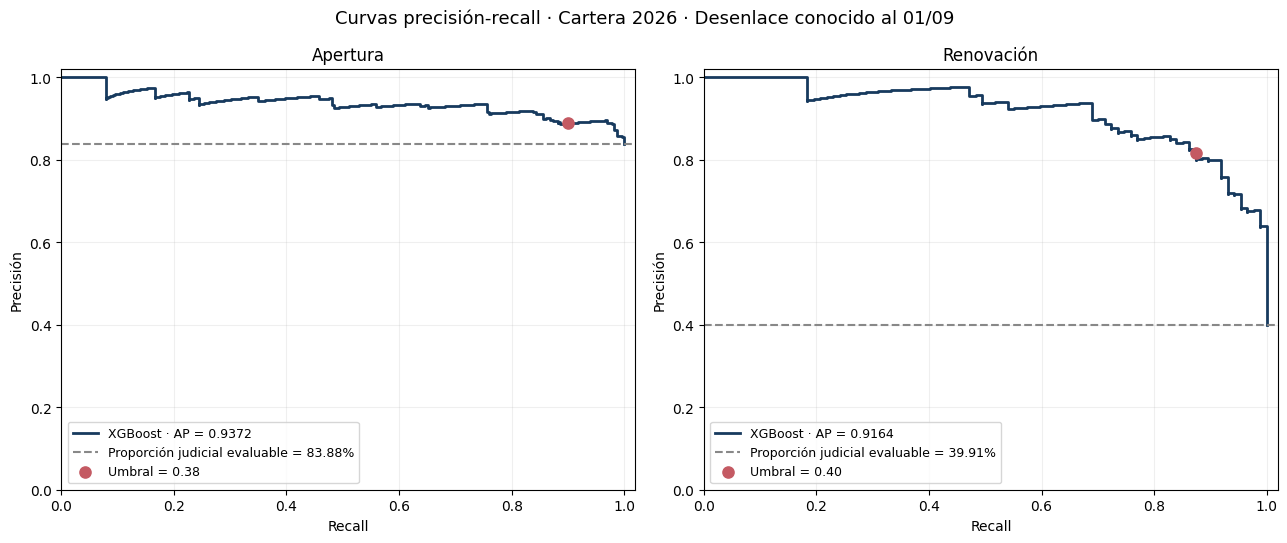

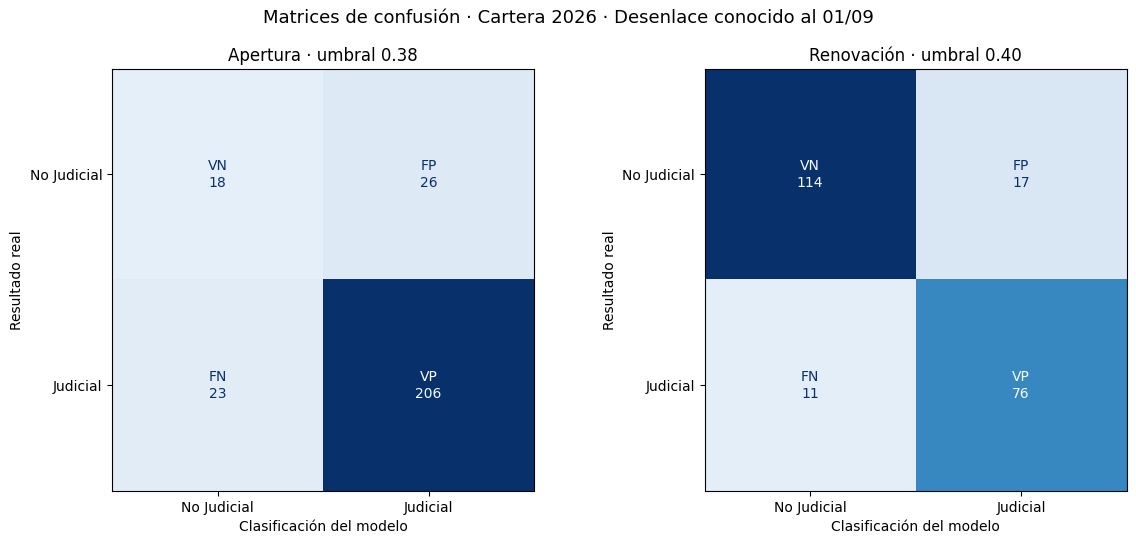

Población,Casos evaluables,PR-AUC (AP),Recall,Precisión,Umbral
Apertura,273,0.9372,89.96%,88.79%,0.38
Renovación,218,0.9164,87.36%,81.72%,0.40


,Población,Umbral,VN,FP,FN,VP
0,Apertura,0.38,18,26,23,206
1,Renovación,0.40,114,17,11,76


In [ ]:
from sklearn.metrics import precision_recall_curve, ConfusionMatrixDisplay

filas_curvas = []
filas_matrices = []
fig_pr, axes_pr = plt.subplots(1, 2, figsize=(13, 5.5))
fig_mc, axes_mc = plt.subplots(1, 2, figsize=(12, 5.5))
for ax_pr, ax_mc, nombre in zip(axes_pr, axes_mc, ['Apertura', 'Renovación']):
    sub = evaluables[evaluables['poblacion_modelo'].eq(nombre)]
    if sub.empty:
        ax_pr.set_title(f'{nombre}: sin casos evaluables')
        ax_mc.set_title(f'{nombre}: sin casos evaluables')
        continue
    y = sub['judicial_real'].astype(int).to_numpy()
    proba = sub['prob_judicial'].to_numpy()
    pred = sub['pred_judicial'].astype(int).to_numpy()
    matriz = confusion_matrix(y, pred, labels=[0, 1])
    vn, fp, fn, vp = matriz.ravel()
    filas_matrices.append({'Población': nombre, 'Umbral': UMBRALES_FINAL[nombre],
                           'VN': int(vn), 'FP': int(fp), 'FN': int(fn), 'VP': int(vp)})
    disp = ConfusionMatrixDisplay(matriz, display_labels=['No Judicial', 'Judicial'])
    disp.plot(ax=ax_mc, cmap='Blues', colorbar=False, values_format='d', im_kw={'vmin': 0})
    for (fila, columna), texto in np.ndenumerate(disp.text_):
        etiqueta = [['VN', 'FP'], ['FN', 'VP']][fila][columna]
        texto.set_text(f'{etiqueta}\n{matriz[fila, columna]:,}'.replace(',', '.'))
    ax_mc.set_xlabel('Clasificación del modelo')
    ax_mc.set_ylabel('Resultado real')
    ax_mc.set_title(f'{nombre} · umbral {UMBRALES_FINAL[nombre]:.2f}')
    if len(np.unique(y)) < 2:
        ax_pr.set_title(f'{nombre}: no están presentes ambas clases')
        continue
    precision_curva, recall_curva, _ = precision_recall_curve(y, proba)
    ap = average_precision_score(y, proba)
    prevalencia = float(y.mean())
    rec = recall_score(y, pred, zero_division=0)
    pre = precision_score(y, pred, zero_division=0)
    ax_pr.step(recall_curva, precision_curva, where='post', color='#173A5E', linewidth=2,
               label=f'XGBoost · AP = {ap:.4f}')
    ax_pr.axhline(prevalencia, color='#888888', linestyle='--',
                  label=f'Proporción judicial evaluable = {prevalencia:.2%}')
    ax_pr.scatter(rec, pre, color='#C45A63', s=65, zorder=4,
                   label=f'Umbral = {UMBRALES_FINAL[nombre]:.2f}')
    ax_pr.set(title=nombre, xlabel='Recall', ylabel='Precisión', xlim=(0, 1.02), ylim=(0, 1.02))
    ax_pr.grid(alpha=.2)
    ax_pr.legend(loc='lower left', fontsize=9)
    filas_curvas.append({'Población': nombre, 'Casos evaluables': len(sub), 'PR-AUC (AP)': ap,
                         'Recall': rec, 'Precisión': pre, 'Umbral': UMBRALES_FINAL[nombre]})
fig_pr.suptitle('Curvas precisión-recall · Cartera 2026 · Desenlace conocido al 01/09', fontsize=13)
fig_pr.tight_layout()
fig_pr.savefig(BASE_DIR / 'CURVAS_PRECISION_RECALL_2026.png', dpi=180, bbox_inches='tight', facecolor='white')
fig_mc.suptitle('Matrices de confusión · Cartera 2026 · Desenlace conocido al 01/09', fontsize=13)
fig_mc.tight_layout()
fig_mc.savefig(BASE_DIR / 'MATRICES_CONFUSION_2026.png', dpi=180, bbox_inches='tight', facecolor='white')
plt.show()
tabla_resumen_curvas = pd.DataFrame(filas_curvas)
tabla_matrices_2026 = pd.DataFrame(filas_matrices)
display(tabla_resumen_curvas.style.format({'PR-AUC (AP)': '{:.4f}', 'Recall': '{:.2%}', 'Precisión': '{:.2%}', 'Umbral': '{:.2f}'}).hide(axis='index'))
display(tabla_matrices_2026)
for _, fila in tabla_matrices_2026.iterrows():
    met = tabla_metricas_2026[tabla_metricas_2026['Población'].eq(fila['Población'])].iloc[0]
    assert all(int(met[c]) == int(fila[c]) for c in ['VN', 'FP', 'FN', 'VP'])


## 17. Exportación de las predicciones y resultados

In [ ]:
with pd.ExcelWriter(RUTA_RESULTADOS_2026, engine='openpyxl') as writer:
    tabla_cfg.to_excel(writer, sheet_name='Configuracion_Final', index=False)
    tabla_control_entrada.to_excel(writer, sheet_name='Control_Entrada', index=False)
    tabla_alertas.to_excel(writer, sheet_name='Alertas_2026', index=False)
    tabla_validacion.to_excel(writer, sheet_name='Derivaciones_Reales', index=False)
    tabla_metricas_2026.to_excel(writer, sheet_name='Metricas_Desenlace', index=False)
    tabla_resumen_curvas.to_excel(writer, sheet_name='Resumen_Curvas_PR', index=False)
    tabla_matrices_2026.to_excel(writer, sheet_name='Matrices_Confusion', index=False)
    tabla_score.to_excel(writer, sheet_name='Resultados_por_Score', index=False)
    tabla_situaciones.to_excel(writer, sheet_name='Situacion_Alertas', index=False)
    resultado_2026.to_excel(writer, sheet_name='Prestamos_2026', index=False)
    cancelados_al_corte.to_excel(writer, sheet_name='Cancelados_01_04', index=False)
    if len(otros_estados_al_corte):
        otros_estados_al_corte.to_excel(writer, sheet_name='Otros_Estados_01_04', index=False)
    if len(sin_poblacion_2026):
        sin_poblacion_2026.to_excel(writer, sheet_name='Sin_Poblacion', index=False)
    if len(inconsistencias):
        inconsistencias.to_excel(writer, sheet_name='Revisar_Fechas', index=False)
    if len(sin_cruce):
        sin_cruce.to_excel(writer, sheet_name='Sin_Cruce_01_09', index=False)

print('Modelos:', RUTA_MODELO_APERTURA, RUTA_MODELO_RENOVACION, sep=' | ')
print('Resultados:', RUTA_RESULTADOS_2026)

Modelos: | /content/drive/MyDrive/PROYECTO TESIS/SEMINARIO/MODELO_FINAL_APERTURA_XGB_SEGMENTADO.joblib | /content/drive/MyDrive/PROYECTO TESIS/SEMINARIO/MODELO_FINAL_RENOVACION_XGB_SEGMENTADO.joblib
Resultados: /content/drive/MyDrive/PROYECTO TESIS/SEMINARIO/RESULTADOS_VALIDACION_2026_AL_01_09.xlsx


## Descripción de los resultados exportados

La hoja **Alertas_2026** contiene la clasificación de los préstamos que permanecían activos al 01/04/2026. La hoja **Derivaciones_Reales** muestra cuáles de los préstamos derivados a Gestión Judicial hasta el 01/09/2026 habían sido detectados previamente por el modelo.

La hoja **Metricas_Desenlace** presenta los VP, FN, FP, VN, recall, precisión, F1, F2 y PR-AUC calculados únicamente sobre los préstamos cuyo desenlace era conocido al 01/09/2026. Los préstamos que continuaban activos a esa fecha permanecen pendientes de observación y no se consideran automáticamente falsos positivos ni verdaderos negativos.

La variable `saldo_real_pase` se conserva para el posterior análisis del saldo al momento de la derivación. Esta variable no participa en la clasificación del riesgo.

## Conclusión

La clasificación utiliza 14 variables en Apertura y 20 en Renovación, con la configuración recibida del notebook 02. Las alertas se guardan antes de consultar los resultados reales. La síntesis siguiente se genera con los resultados de esta ejecución.

In [ ]:
from IPython.display import Markdown
resumen = tabla_validacion[tabla_validacion['Población'].eq('TOTAL')].iloc[0]
alertas = tabla_alertas[tabla_alertas['Población'].eq('TOTAL')].iloc[0]
met = tabla_metricas_2026[tabla_metricas_2026['Población'].eq('TOTAL')].iloc[0]
display(Markdown(
    f"Se clasificaron **{int(alertas['Préstamos 2026']):,} operaciones**, de las cuales "
    f"**{int(alertas['Alertas judiciales']):,}** recibieron alerta. Al cruzar estas predicciones "
    f"con los resultados reales hasta el 01/09/2026, se identificaron "
    f"**{int(resumen['Detectados'])} de {int(resumen['Judiciales reales'])} casos judiciales** "
    f"(recall del **{resumen['Recall observado']:.2%}**), con "
    f"**{int(resumen['No detectados'])} casos no detectados**. "
    f"La precisión fue del **{met['Precisión']:.2%}** sobre "
    f"**{int(met['Casos con desenlace conocido'])} operaciones con desenlace conocido**. "
    "Los préstamos que continúan activos se conservan para seguimiento y no se contabilizan como errores."
))


Se clasificaron **3,032 operaciones**, de las cuales **1,929** recibieron alerta. Al cruzar estas predicciones con los resultados reales hasta el 01/09/2026, se identificaron **282 de 316 casos judiciales** (recall del **89.24%**), con **34 casos no detectados**. La precisión fue del **86.77%** sobre **491 operaciones con desenlace conocido**. Los préstamos que continúan activos se conservan para seguimiento y no se contabilizan como errores.